# Guía de Práctica N.° 09 — Regresión lineal simple
**Análisis de Datos (SIS323) · Universidad Nacional del Altiplano – Puno · 2026-II**

**Datos:** 320 departamentos simulados de Puno y Juliaca.  
**Objetivo:** Ajustar e interpretar una regresión lineal simple del precio de alquiler según el área.
**Integrantes:** Mamani Zapana Edward, Gutierrez Arratia Kevin Diego, Mamani Panca Roger Golber

## Paso 1. Explorar la relación entre área y precio
Se revisa las dimensiones, las primeras filas y la correlación de Pearson.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

alq = pd.read_csv("alquilerespunojuliacacsv.csv")
print(alq.shape)
print(alq.head(3).T)
print("Correlación de Pearson área–precio:", round(alq["area_m2"].corr(alq["precio_soles"]), 2))

(320, 9)
                        0        1     2
ciudad               Puno  Juliaca  Puno
area_m2                86      109    77
habitaciones            3        3     4
banos                   2        1     2
distancia_centro_km   5.8      2.2   0.3
antiguedad_anios       20       15     4
cochera                Sí       No    No
internet_fibra         No       No    No
precio_soles         1030     1040  1090
Correlación de Pearson área–precio: 0.82


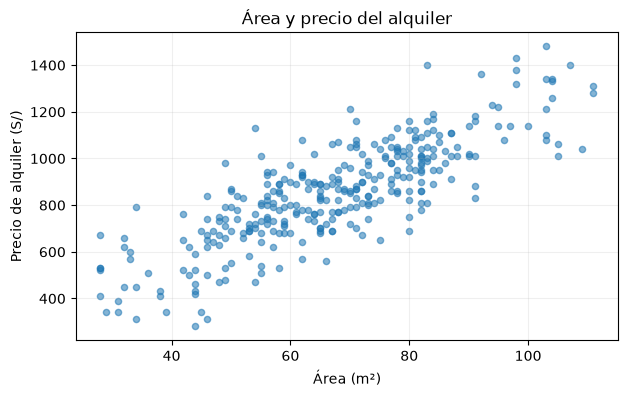

In [2]:
plt.figure(figsize=(7, 4))
plt.scatter(alq["area_m2"], alq["precio_soles"], s=20, alpha=0.55)
plt.xlabel("Área (m²)")
plt.ylabel("Precio de alquiler (S/)")
plt.title("Área y precio del alquiler")
plt.grid(alpha=0.2)
plt.show()

## Paso 2. Ajustar el modelo con Scikit-learn
Obtener la intersección, la pendiente y las estimaciones para departamentos de 60 y 85 m².

In [3]:
from sklearn.linear_model import LinearRegression

X = alq[["area_m2"]]
y = alq["precio_soles"]
modelo = LinearRegression().fit(X, y)
b0, b1 = modelo.intercept_, modelo.coef_[0]
print(f"Intersección (β0): {b0:.1f} soles")
print(f"Pendiente (β1): {b1:.2f} soles por m²")
print(f"Precio estimado de 60 m²: S/ {modelo.predict(pd.DataFrame({'area_m2': [60]}))[0]:.0f}")
print(f"Precio estimado de 85 m²: S/ {modelo.predict(pd.DataFrame({'area_m2': [85]}))[0]:.0f}")

Intersección (β0): 170.6 soles
Pendiente (β1): 10.18 soles por m²
Precio estimado de 60 m²: S/ 782
Precio estimado de 85 m²: S/ 1036


## Paso 3. Interpretar la pendiente


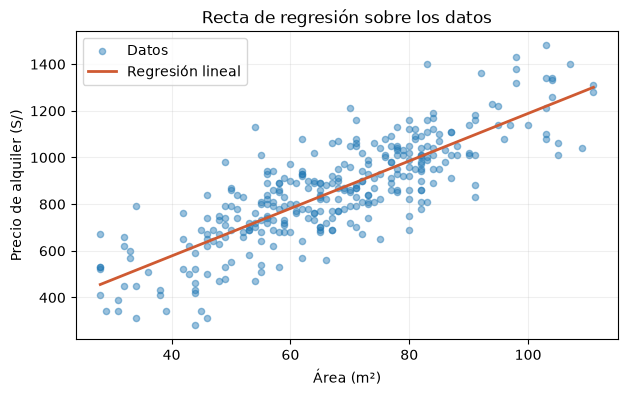

In [4]:
plt.figure(figsize=(7, 4))
plt.scatter(alq["area_m2"], y, s=20, alpha=0.45, label="Datos")
orden = X["area_m2"].sort_values()
plt.plot(orden, modelo.predict(pd.DataFrame({"area_m2": orden})),
         color="#cf5a32", linewidth=2, label="Regresión lineal")
plt.xlabel("Área (m²)")
plt.ylabel("Precio de alquiler (S/)")
plt.title("Recta de regresión sobre los datos")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Paso 4. Calcular y graficar los residuos
Calcular la diferencia entre precio observado y precio estimado y revisar su distribución frente a los valores ajustados.

Media de los residuos: 0.00 (por construcción, cercana a 0)
Desviación de los residuos: 127.0 soles


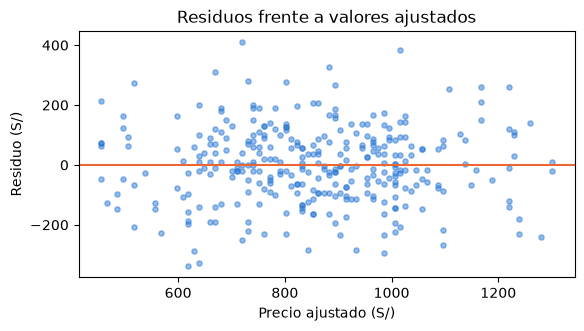

In [5]:
alq["ajustado"] = modelo.predict(X)
alq["residuo"] = y - alq["ajustado"]
print(f"Media de los residuos: {alq['residuo'].mean():.2f} (por construcción, cercana a 0)")
print(f"Desviación de los residuos: {alq['residuo'].std():.1f} soles")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.scatter(alq["ajustado"], alq["residuo"], s=14, alpha=0.5, color="#2a78d6")
ax.axhline(0, color="#eb6834", lw=1.5)
ax.set_xlabel("Precio ajustado (S/)")
ax.set_ylabel("Residuo (S/)")
ax.set_title("Residuos frente a valores ajustados")
plt.show()

## Paso 5. Revisar los supuestos
Evaluar linealidad, independencia, varianza constante y normalidad de los residuos. La independencia requiere considerar cómo se obtuvieron los datos simulados.

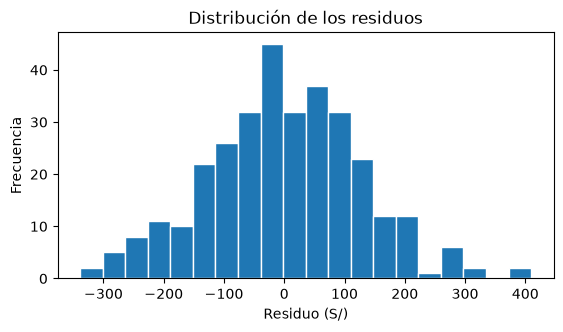

In [6]:
plt.figure(figsize=(6.4, 3.2))
plt.hist(alq["residuo"], bins=20, edgecolor="white")
plt.xlabel("Residuo (S/)")
plt.ylabel("Frecuencia")
plt.title("Distribución de los residuos")
plt.show()

## Paso 6. Interpretar para un público no técnico
Calcular el error absoluto medio como referencia del error típico y el rango de áreas observado. Redactar después la interpretación para la inmobiliaria.

In [7]:
from sklearn.metrics import mean_absolute_error

print(f"Error absoluto medio (MAE): S/ {mean_absolute_error(y, alq['ajustado']):.1f}")
print(f"Área mínima: {alq['area_m2'].min()} m²")
print(f"Área máxima: {alq['area_m2'].max()} m²")

Error absoluto medio (MAE): S/ 99.9
Área mínima: 28 m²
Área máxima: 111 m²
